# 1. Librerías

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Modelos individuales
from sklearn.decomposition import PCA
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.svm import SVC
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import ValidationCurveDisplay, cross_val_predict

# Modelos extra para ensemble
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import VotingClassifier

# Variables de inicio
import utils.constantes as cte
from utils import modelado as mod

%matplotlib inline

np.random.seed(cte.semilla)

# 2. Train - Test

Datos provenientes de EDA, depurados pero con registros nulos aún, con partición estratificada 80% train, 20% test.

In [118]:
# Misma partición del grupo.
X_train, X_test, y_train, y_test = mod.cargar_datos()

print("Train:", X_train.shape)
print("Proporción de clases:",y_train.value_counts(normalize=True).sort_index().round(2).to_dict())

Train: (1803, 30)
Proporción de clases: {0: 0.5, 1: 0.3, 2: 0.2}


In [119]:
def curva_validacion(busqueda, parametro, valores, titulo):
    """Representa train y validación con media ± desviación, modificando un hiperparámetro."""

    ValidationCurveDisplay.from_estimator(
        busqueda.best_estimator_, X_train,y_train,
        param_name=parametro,
        param_range=valores,
        cv=mod.validador,
        scoring=mod.metrica,
        std_display_style="fill_between",
        n_jobs=-1
    )

    plt.title(titulo)
    plt.ylabel("F1 macro")
    plt.show()

# 3. Balanceo

In [120]:
rejilla_lda = [
    #Solver minimos cuadrados, con covarianza regularizada según el ruido
    {"modelo__solver": ["lsqr"],
    "modelo__shrinkage": [None, "auto", 0.1, 0.5, 0.9],},
    #Solver con descomposición de autovalores, con covarianza regularizada según el ruido
    {"modelo__solver": ["eigen"],
    "modelo__shrinkage": [None, "auto", 0.1, 0.5, 0.9],},]

busquedas_lda, tablas_balanceo_lda = {}, []

# LDA no admite class_weight, probamos sin balanceo, SMOTENC y los dos métodos de undersampling
for balanceo in [None, "smotenc", "tomek", "enn"]:
    busqueda = mod.crear_busqueda(mod.crear_pipeline(LinearDiscriminantAnalysis(),balanceo=balanceo), rejilla_lda)
    busquedas_lda[balanceo] = busqueda.fit(X_train,y_train)
    tablas_balanceo_lda.append(mod.tabla_resultados(busqueda,f"lda | {balanceo}"))

balanceo_resultados_lda = pd.concat(tablas_balanceo_lda)
display(balanceo_resultados_lda[["f1_macro_val","f1_macro_val_std","recall_alto_val","recall_alto_val_std","precision_alto_val","diferencia_train_val"]].round(3)
)

print("\nMejores hiperparámetros:\n")

for modelo, params in balanceo_resultados_lda["mejores_parametros"].items():
    print(f"{modelo}:")
    print(params)
    print()

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
lda | None,0.660,0.038,0.681,0.059,0.698,0.017
lda | smotenc,0.636,0.028,0.759,0.052,0.611,0.021
lda | tomek,0.647,0.040,0.717,0.069,0.675,0.019
lda | enn,0.567,0.034,0.823,0.055,0.571,0.017



Mejores hiperparámetros:

lda | None:
{'modelo__shrinkage': 0.1, 'modelo__solver': 'lsqr'}

lda | smotenc:
{'modelo__shrinkage': 0.5, 'modelo__solver': 'lsqr'}

lda | tomek:
{'modelo__shrinkage': 'auto', 'modelo__solver': 'lsqr'}

lda | enn:
{'modelo__shrinkage': None, 'modelo__solver': 'lsqr'}



In [121]:
rejilla_svm = [
    # Kernel lineal: Frontera plana
    {"modelo__kernel": ["linear"],
    "modelo__C": [0.1, 1, 10, 100],},
    # Kernel RBF: Frontera curva
    {"modelo__kernel": ["rbf"],
    "modelo__C": [0.1, 1, 10, 100],
    "modelo__gamma": ["scale", "auto", 0.01, 0.1],},
    # Kernel polinómico: Frontera adaptada a polinomio
    {"modelo__kernel": ["poly"],
    "modelo__C": [0.1, 1, 10],
    "modelo__degree": [2, 3],
    "modelo__gamma": ["scale", "auto"],},
    # Kernel sigmoide: Frontera adaptada a sigmoide
    {"modelo__kernel": ["sigmoid"],
    "modelo__C": [0.1, 1, 10],
    "modelo__gamma": ["scale", "auto"],},]

busquedas_svm, tablas_balanceo_svm = {}, []

# SVM admite class_weight, así que probamos todas las estrategias

for balanceo in [None, "class_weight", "smotenc", "tomek", "enn"]:

    busqueda = mod.crear_busqueda(mod.crear_pipeline(SVC(),balanceo=balanceo),rejilla_svm)
    busquedas_svm[balanceo] = busqueda.fit(X_train,y_train)
    tablas_balanceo_svm.append(mod.tabla_resultados(busqueda,f"svm | {balanceo}"))

    # mejor modelo encontrado
    # mejor_modelo = busquedas_svm[balanceo].best_estimator_
    # y_pred = mejor_modelo.predict(X_test)
    # print(f"\n===== {balanceo} =====")
    # print("Clases reales:")
    # print(pd.Series(y_test).value_counts().sort_index())
    # print("\nClases predichas:")
    # print(pd.Series(y_pred).value_counts().sort_index())

balanceo_resultados_svm = pd.concat(tablas_balanceo_svm)
display(balanceo_resultados_svm[["f1_macro_val","f1_macro_val_std","recall_alto_val","recall_alto_val_std","precision_alto_val","diferencia_train_val"        ]].round(3))
for modelo, params in balanceo_resultados_svm["mejores_parametros"].items():
    print(f"{modelo}:")
    print(params)
    print()

/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/metrics/_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(ave

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
svm | None,0.649,0.029,0.676,0.041,0.694,0.026
svm | class_weight,0.648,0.018,0.728,0.045,0.644,0.185
svm | smotenc,0.636,0.022,0.726,0.054,0.636,0.116
svm | tomek,0.643,0.024,0.698,0.051,0.658,0.092
svm | enn,0.556,0.034,0.809,0.064,0.563,0.041


svm | None:
{'modelo__C': 0.1, 'modelo__kernel': 'linear'}

svm | class_weight:
{'modelo__C': 1, 'modelo__gamma': 'scale', 'modelo__kernel': 'rbf'}

svm | smotenc:
{'modelo__C': 1, 'modelo__gamma': 'auto', 'modelo__kernel': 'rbf'}

svm | tomek:
{'modelo__C': 10, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}

svm | enn:
{'modelo__C': 100, 'modelo__kernel': 'linear'}



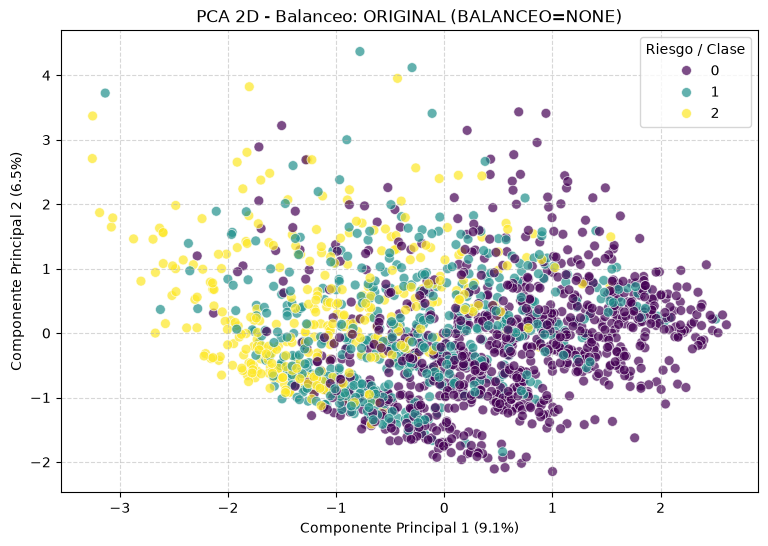

[Original (Balanceo=None)] Muestras: 1803 | Varianza explicada acumulada (PC1 + PC2): 15.52%



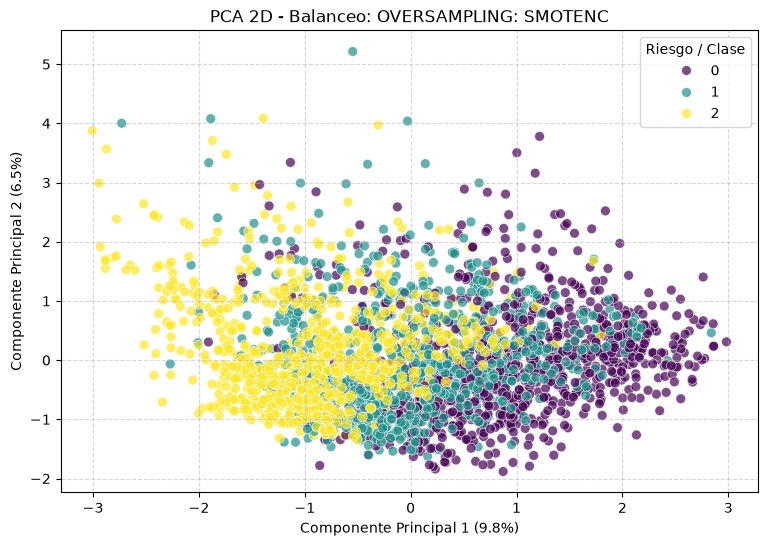

[Oversampling: SMOTENC] Muestras: 2703 | Varianza explicada acumulada (PC1 + PC2): 16.28%



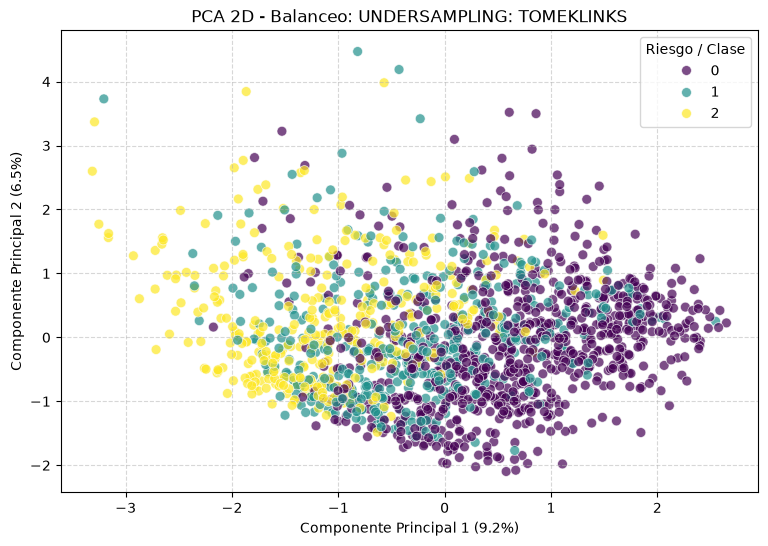

[Undersampling: TomekLinks] Muestras: 1621 | Varianza explicada acumulada (PC1 + PC2): 15.69%



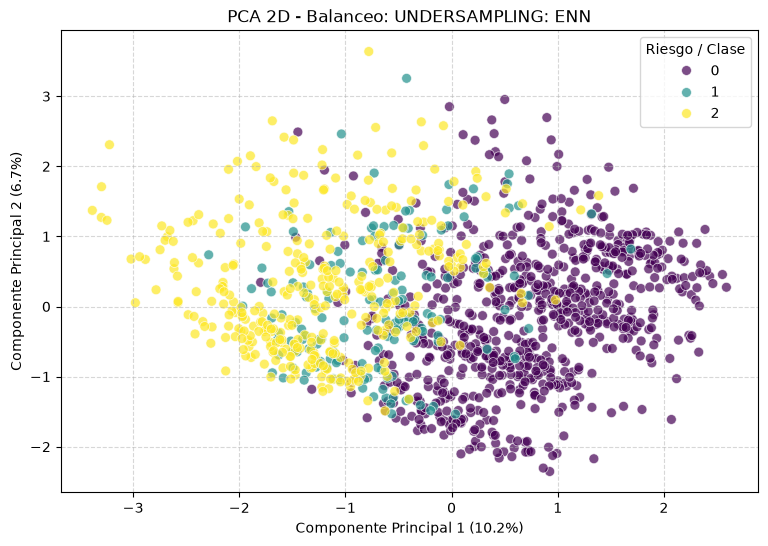

[Undersampling: ENN] Muestras: 1281 | Varianza explicada acumulada (PC1 + PC2): 16.81%



In [173]:
def graficar_pca_2d(metodo_balanceo, titulo):
    if metodo_balanceo is None:
        # Pipeline solo con preprocesado (imputación con mediana + RobustScaler)
        pipeline_temp = mod.crear_pipeline(LinearDiscriminantAnalysis(), balanceo=None)
        X_train_prep = pipeline_temp.named_steps['preprocesado'].fit_transform(X_train, y_train)
        X_res, y_res = X_train_prep, y_train
    else:
        # Pipeline completo con el balanceo correspondiente ("tomek" o "enn")
        pipeline_bal = mod.crear_pipeline(LinearDiscriminantAnalysis(), balanceo=metodo_balanceo)
        pasos_pre = pipeline_bal.named_steps['preprocesado']
        X_train_prep = pasos_pre.fit_transform(X_train, y_train)
        paso_bal = pipeline_bal.named_steps['balanceo']
        X_res, y_res = paso_bal.fit_resample(X_train_prep, y_train)
    
    # Aplicar PCA a 2 dimensiones
    pca = PCA(n_components=2, random_state=cte.semilla)
    X_res_pca = pca.fit_transform(X_res)
    
    # Crear DataFrame para 2D
    df_pca = pd.DataFrame(X_res_pca, columns=['PC1', 'PC2'])
    df_pca['Clase'] = y_res.values
    
    # 3. Visualización en 2D con Seaborn
    plt.figure(figsize=(9, 6))
    sns.scatterplot(
        x='PC1', y='PC2', 
        hue='Clase', 
        data=df_pca, 
        palette='viridis', 
        alpha=0.7,
        s=50
    )
    
    plt.title(f"PCA 2D - Balanceo: {titulo.upper()}")
    plt.xlabel(f"Componente Principal 1 ({pca.explained_variance_ratio_[0]*100:.1f}%)")
    plt.ylabel(f"Componente Principal 2 ({pca.explained_variance_ratio_[1]*100:.1f}%)")
    plt.legend(title="Riesgo / Clase")
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.show()
    
    print(f"[{titulo}] Muestras: {len(X_res)} | Varianza explicada acumulada (PC1 + PC2): {sum(pca.explained_variance_ratio_)*100:.2f}%\n")

# Datos originales (imputados y escalados, sin undersampling) 
graficar_pca_2d(None, "Original (Balanceo=None)")

# Datos originales (imputados y escalados, sin undersampling) 
graficar_pca_2d("smotenc", "Oversampling: SMOTENC")

# Con TomekLinks
graficar_pca_2d("tomek", "Undersampling: TomekLinks")

# Con ENN
graficar_pca_2d("enn", "Undersampling: ENN")

**Conclusión**

- El balanceo no mejora el rendimiento global de forma consistente. Los mejores valores de F1 macro se obtienen sin balanceo (LDA) y en (SVM), mientras que SMOTENC y ENN no aportan mejoras claras.

- Las técnicas de balanceo aumentan el recall de riesgo alto, pero reducen la precisión. Se detectan más pacientes de alto riesgo, aunque a costa de generar más falsas alarmas.

- TomekLinks ofrece el mejor compromiso entre sensibilidad y rendimiento global. Mejora ligeramente el recall manteniendo un F1 macro cercano al de los datos originales.

- ENN resulta demasiado agresivo. Aunque consigue los mayores recalls para la clase de riesgo alto, produce la mayor caída en F1 macro, por lo que no parece adecuado para este conjunto de datos.

- Los resultados sugieren que el principal problema es el solapamiento entre clases más que el desbalance (50%-30%-20%). Por ello, se seleccionan para los siguientes experimentos las configuraciones con mejor F1 macro: LDA sin balanceo y SVM sin balanceo.

***Durante la búsqueda de hiperparámetros algunas configuraciones de SVM, especialmente determinados kernels polinómicos y combinaciones con valores bajos de C, llegaron a ignorar completamente alguna de las clases, generando advertencias de sklearn sobre precisiones indefinidas***

***Pese a que None arroja valores más robustos, vale la pena valorar tomek que es el segundo valor más atractivo en LDA y el tercero en SVM (smoteenc es el segundo pero tiene mucha diferencia entre arain y test), por lo tanto se valorará también arrojar los resultados con tomek***

# 4. Modelo sin Balancear (None)

## 4.1. SVM

`kernel`: tipo de frontera de decisión.
- linear: genera una frontera lineal.
- rbf: permite fronteras no lineales mediante funciones gaussianas.
- poly: utiliza transformaciones polinómicas.
- sigmoid: comportamiento similar a una neurona artificial.

`C`: penalización de los errores de clasificación.
- Valores pequeños (0.1) generan fronteras más simples.
- Valores grandes (10, 100) intentan clasificar correctamente más observaciones y pueden aumentar el sobreajuste.

`gamma`: controla la influencia de cada observación.
- Valores pequeños producen fronteras suaves.
- Valores grandes permiten fronteras más complejas.
- "scale" y "auto" calculan automáticamente el valor a partir de las características del conjunto de datos.

`degree`: grado del polinomio cuando se utiliza kernel="poly".

In [122]:
# la búsqueda óptima se obtuvo con None en el experimento de balanceo

busqueda_svm = busquedas_svm[None]

print("Mejores parámetros:", busqueda_svm.best_params_)

tabla_svm = mod.tabla_resultados(busqueda_svm, "svm")
mod.guardar_resultados(busqueda_svm, "svm")

tabla_svm.round(3).T

Mejores parámetros: {'modelo__C': 0.1, 'modelo__kernel': 'linear'}


modelo,svm
f1_macro_train,0.675
f1_macro_train_std,0.011
f1_macro_val,0.649
f1_macro_val_std,0.029
precision_macro_train,0.683
precision_macro_train_std,0.011
precision_macro_val,0.654
precision_macro_val_std,0.032
recall_macro_train,0.673
recall_macro_train_std,0.01


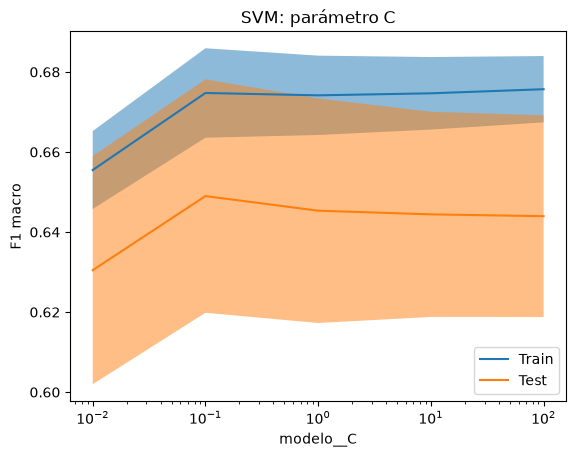

In [123]:
curva_validacion(
    busqueda_svm,
    "modelo__C",
    [0.01, 0.1, 1, 10, 100],
    "SVM: parámetro C"
)

## 4.2. LDA

In [124]:
# la búsqueda óptima se obtuvo sin balanceo en el experimento de balanceo

busqueda_lda = busquedas_lda[None]

print("Mejores parámetros:", busqueda_lda.best_params_)

tabla_lda = mod.tabla_resultados(busqueda_lda, "lda")
mod.guardar_resultados(busqueda_lda, "lda")

tabla_lda.round(3).T

Mejores parámetros: {'modelo__shrinkage': 0.1, 'modelo__solver': 'lsqr'}


modelo,lda
f1_macro_train,0.677
f1_macro_train_std,0.01
f1_macro_val,0.66
f1_macro_val_std,0.038
precision_macro_train,0.684
precision_macro_train_std,0.01
precision_macro_val,0.666
precision_macro_val_std,0.042
recall_macro_train,0.675
recall_macro_train_std,0.009


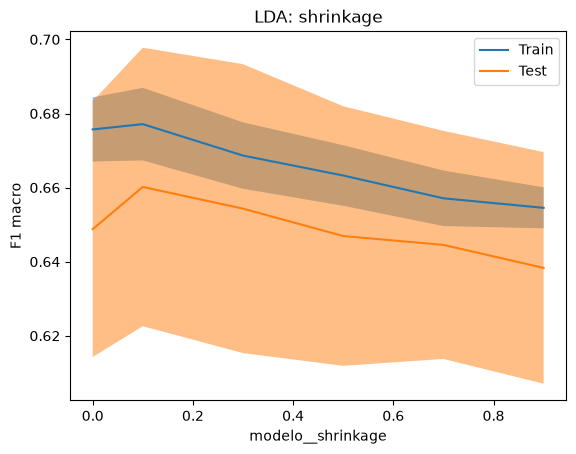

In [125]:
curva_validacion(
    busqueda_lda,
    "modelo__shrinkage",
    [0.0, 0.1, 0.3, 0.5, 0.7, 0.9],
    "LDA: shrinkage"
)

## 4.3. Comparación de modelos

In [126]:
busquedas = {"lda": busqueda_lda,"svm": busqueda_svm,}
comparacion = pd.concat([tabla_lda,tabla_svm,])
display(comparacion[["f1_macro_val","f1_macro_val_std","recall_alto_val","recall_alto_val_std","precision_alto_val","diferencia_train_val"]]
    .sort_values("f1_macro_val",ascending=False).round(3))
print("Mejores hiperparámetros")
display(comparacion[["mejores_parametros"]])


,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
lda,0.660,0.038,0.681,0.059,0.698,0.017
svm,0.649,0.029,0.676,0.041,0.694,0.026


Mejores hiperparámetros


,mejores_parametros
modelo,
lda,"{'modelo__shrinkage': 0.1, 'modelo__solver': '..."
svm,"{'modelo__C': 0.1, 'modelo__kernel': 'linear'}"


**Conclusión**

- LDA obtiene el mejor rendimiento global. Alcanza un F1 macro de 0,660, ligeramente superior al de SVM (0,649), así como un mejor recall de la clase de riesgo alto (0,681 frente a 0,676) y una mayor precisión (0,698 frente a 0,694).

- Ambos modelos muestran una buena capacidad de generalización. La diferencia entre entrenamiento y validación es muy baja en los dos casos (0,017 en LDA y 0,026 en SVM), lo que indica ausencia de sobreajuste importante y una estimación estable del rendimiento futuro.

- La regularización ligera mejora LDA. La curva de validación muestra que los mejores resultados aparecen para valores bajos de shrinkage (≈ 0,1). A medida que aumenta la regularización, el rendimiento en validación disminuye gradualmente, lo que indica que una simplificación excesiva de la matriz de covarianzas elimina información útil para separar las clases.

- SVM alcanza su mejor rendimiento con un modelo lineal sencillo. La curva de validación muestra que el máximo F1 se obtiene para C=0.1, mientras que aumentar la complejidad del modelo no aporta mejoras. Esto sugiere que las relaciones presentes en los datos son relativamente simples y que una frontera de decisión más compleja no mejora la capacidad predictiva.

- Las diferencias entre ambos modelos son pequeñas. Los valores de F1 macro, recall y precisión son muy similares, por lo que ambos constituyen alternativas válidas para el problema. Sin embargo, LDA obtiene sistemáticamente los mejores resultados y presenta el menor sobreajuste, por lo que se considera la opción más adecuada entre los dos modelos analizados.

## 4.4. Comparación de cada fold

In [127]:
folds = pd.DataFrame({
    n: pd.read_csv(
        mod.RUTA_RESULTADOS / f"{n}_folds.csv",
        index_col=0
    )["f1_macro"]
    for n in ["lda", "svm"]
})

folds["svm_menos_lda"] = folds["svm"] - folds["lda"]
folds.round(3)


,lda,svm,svm_menos_lda
fold,,,
0,0.683,0.683,0.000
1,0.709,0.678,-0.031
2,0.613,0.622,0.009
3,0.676,0.652,-0.025
4,0.620,0.610,-0.009


## 4.5. Matrices de confusión

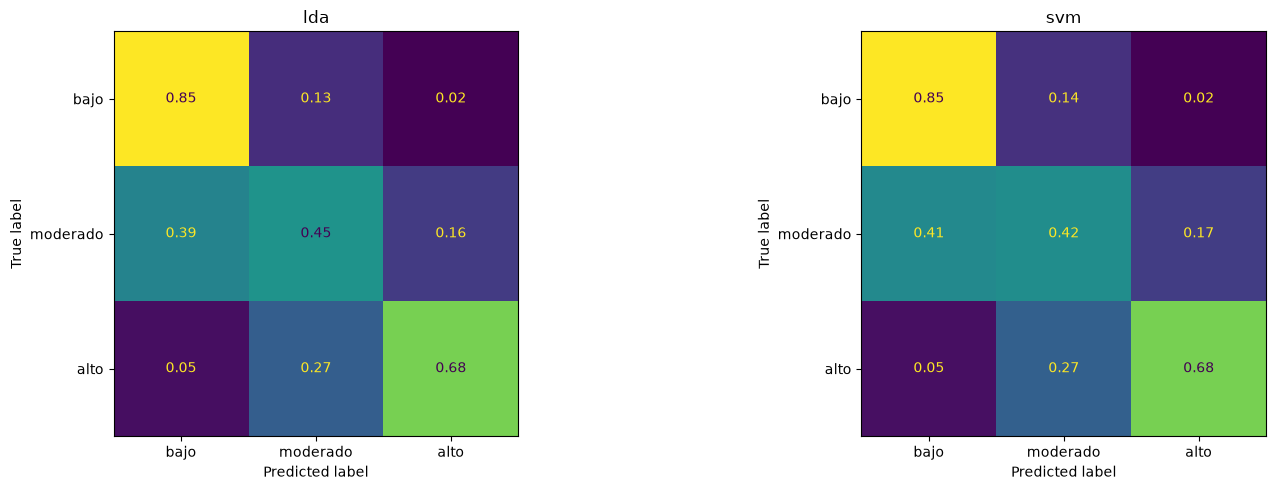

In [128]:

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, (nombre, busqueda) in zip(axes, busquedas.items()):

    y_pred = cross_val_predict(
        busqueda.best_estimator_,
        X_train,
        y_train,
        cv=mod.validador,
        n_jobs=-1
    )

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred,
        display_labels=["bajo", "moderado", "alto"],
        normalize="true",
        values_format=".2f",
        ax=ax,
        colorbar=False
    )

    ax.set_title(nombre)

plt.tight_layout()
plt.show()


### **Conclusión**

| | LDA | SVM |
|---|---|---|
| F1 macro (validación) | **0,660 ± 0,038** | 0,649 ± 0,029 |
| Recall de riesgo alto | **0,681** | 0,676 |
| Riesgo alto clasificado como bajo | **0,05** | 0,05 |
| Precisión de riesgo alto | **0,698** | 0,694 |
| Diferencia train-validación | **0,017** | 0,026 |

- **LDA es el mejor modelo según el criterio acordado**, ya que obtiene el mayor F1 macro y también supera ligeramente a SVM en recall y precisión para la clase de riesgo alto.

- **Ambos modelos generalizan bien**, con diferencias train-validación muy reducidas, lo que indica ausencia de sobreajuste relevante.

- **Las diferencias son pequeñas**, por lo que tanto LDA como SVM constituyen alternativas válidas para el problema.

- **Se selecciona LDA como candidato de este notebook debido a los resultados ligeramente superiores, contando con el problema de separación de clases**

# 5. Modelo con undersampling (Tomek)

## 5.1. SVM

`kernel`: tipo de frontera de decisión.
- linear: genera una frontera lineal.
- rbf: permite fronteras no lineales mediante funciones gaussianas.
- poly: utiliza transformaciones polinómicas.
- sigmoid: comportamiento similar a una neurona artificial.

`C`: penalización de los errores de clasificación.
- Valores pequeños (0.1) generan fronteras más simples.
- Valores grandes (10, 100) intentan clasificar correctamente más observaciones y pueden aumentar el sobreajuste.

`gamma`: controla la influencia de cada observación.
- Valores pequeños producen fronteras suaves.
- Valores grandes permiten fronteras más complejas.
- "scale" y "auto" calculan automáticamente el valor a partir de las características del conjunto de datos.

`degree`: grado del polinomio cuando se utiliza kernel="poly".

In [145]:
busqueda_svm = busquedas_svm["tomek"]

print("Mejores parámetros:", busqueda_svm.best_params_)

tabla_svm = mod.tabla_resultados(busqueda_svm, "svm")
mod.guardar_resultados(busqueda_svm, "svm")

tabla_svm.round(3).T

Mejores parámetros: {'modelo__C': 10, 'modelo__gamma': 0.01, 'modelo__kernel': 'rbf'}


modelo,svm
f1_macro_train,0.735
f1_macro_train_std,0.011
f1_macro_val,0.643
f1_macro_val_std,0.024
precision_macro_train,0.746
precision_macro_train_std,0.01
precision_macro_val,0.646
precision_macro_val_std,0.026
recall_macro_train,0.736
recall_macro_train_std,0.011


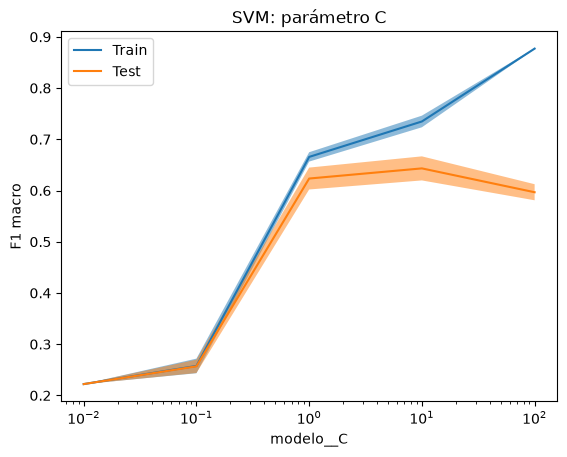

In [146]:
curva_validacion(
    busqueda_svm,
    "modelo__C",
    [0.01, 0.1, 1, 10, 100],
    "SVM: parámetro C"
)

## 5.2. LDA

In [131]:
busqueda_lda = busquedas_lda["tomek"]

print("Mejores parámetros:", busqueda_lda.best_params_)

tabla_lda = mod.tabla_resultados(busqueda_lda, "lda")
mod.guardar_resultados(busqueda_lda, "lda")

tabla_lda.round(3).T

Mejores parámetros: {'modelo__shrinkage': 'auto', 'modelo__solver': 'lsqr'}


modelo,lda
f1_macro_train,0.665
f1_macro_train_std,0.009
f1_macro_val,0.647
f1_macro_val_std,0.04
precision_macro_train,0.671
precision_macro_train_std,0.01
precision_macro_val,0.651
precision_macro_val_std,0.044
recall_macro_train,0.671
recall_macro_train_std,0.009


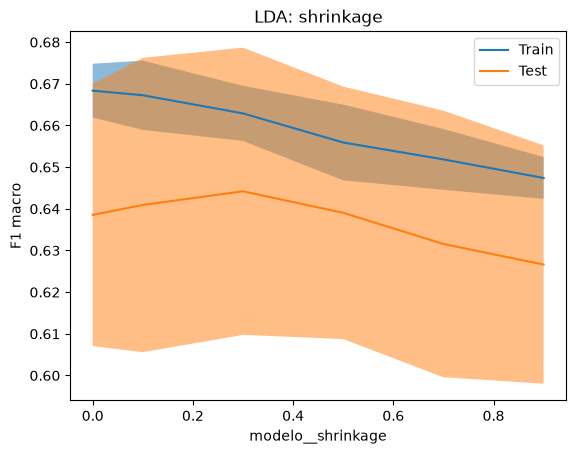

In [132]:
curva_validacion(
    busqueda_lda,
    "modelo__shrinkage",
    [0.0, 0.1, 0.3, 0.5, 0.7, 0.9],
    "LDA: shrinkage"
)

## 5.3. Comparación de modelos

In [133]:
busquedas = {"lda": busqueda_lda,"svm": busqueda_svm,}
comparacion = pd.concat([tabla_lda,tabla_svm,])
display(comparacion[["f1_macro_val","f1_macro_val_std","recall_alto_val","recall_alto_val_std","precision_alto_val","diferencia_train_val"]]
    .sort_values("f1_macro_val",ascending=False).round(3))
print("Mejores hiperparámetros")
display(comparacion[["mejores_parametros"]])


,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
lda,0.647,0.040,0.717,0.069,0.675,0.019
svm,0.643,0.024,0.698,0.051,0.658,0.092


Mejores hiperparámetros


,mejores_parametros
modelo,
lda,"{'modelo__shrinkage': 'auto', 'modelo__solver'..."
svm,"{'modelo__C': 10, 'modelo__gamma': 0.01, 'mode..."


**Conclusión**

- LDA obtiene el mejor rendimiento global. Alcanza un F1 macro de 0,660, ligeramente superior al de SVM (0,649), así como un mejor recall de la clase de riesgo alto (0,681 frente a 0,676) y una mayor precisión (0,698 frente a 0,694).

- Ambos modelos muestran una buena capacidad de generalización. La diferencia entre entrenamiento y validación es muy baja en los dos casos (0,017 en LDA y 0,026 en SVM), lo que indica ausencia de sobreajuste importante y una estimación estable del rendimiento futuro.

- La regularización ligera mejora LDA. La curva de validación muestra que los mejores resultados aparecen para valores bajos de shrinkage (≈ 0,1). A medida que aumenta la regularización, el rendimiento en validación disminuye gradualmente, lo que indica que una simplificación excesiva de la matriz de covarianzas elimina información útil para separar las clases.

- SVM alcanza su mejor rendimiento con un modelo lineal sencillo. La curva de validación muestra que el máximo F1 se obtiene para C=0.1, mientras que aumentar la complejidad del modelo no aporta mejoras. Esto sugiere que las relaciones presentes en los datos son relativamente simples y que una frontera de decisión más compleja no mejora la capacidad predictiva.

- Las diferencias entre ambos modelos son pequeñas. Los valores de F1 macro, recall y precisión son muy similares, por lo que ambos constituyen alternativas válidas para el problema. Sin embargo, LDA obtiene sistemáticamente los mejores resultados y presenta el menor sobreajuste, por lo que se considera la opción más adecuada entre los dos modelos analizados.

## 4.4. Comparación de cada fold

In [134]:
folds = pd.DataFrame({
    n: pd.read_csv(
        mod.RUTA_RESULTADOS / f"{n}_folds.csv",
        index_col=0
    )["f1_macro"]
    for n in ["lda", "svm"]
})

folds["svm_menos_lda"] = folds["svm"] - folds["lda"]
folds.round(3)


,lda,svm,svm_menos_lda
fold,,,
0,0.650,0.665,0.015
1,0.704,0.675,-0.028
2,0.600,0.612,0.012
3,0.676,0.637,-0.039
4,0.604,0.627,0.023


## 4.5. Matrices de confusión

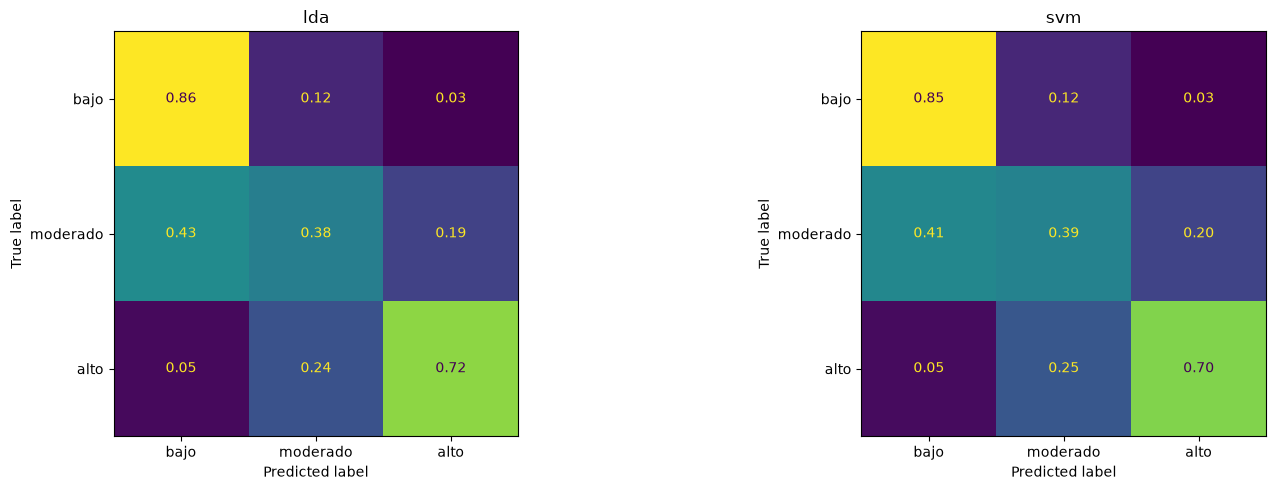

In [135]:

fig, axes = plt.subplots(1, 2, figsize=(16, 5))

for ax, (nombre, busqueda) in zip(axes, busquedas.items()):

    y_pred = cross_val_predict(
        busqueda.best_estimator_,
        X_train,
        y_train,
        cv=mod.validador,
        n_jobs=-1
    )

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred,
        display_labels=["bajo", "moderado", "alto"],
        normalize="true",
        values_format=".2f",
        ax=ax,
        colorbar=False
    )

    ax.set_title(nombre)

plt.tight_layout()
plt.show()


### **Conclusión**

| Métrica | LDA | SVM |
|---|---:|---:|
| F1 macro (validación) | **0,647 ± 0,040** | 0,643 ± 0,024 |
| Recall de riesgo alto | **0,717 ± 0,069** | 0,698 ± 0,051 |
| Riesgo alto clasificado como bajo | **0,05** | 0,05 |
| Precision de riesgo alto | **0,675 ± 0,058** | 0,658 ± 0,046 |
| Diferencia train-validación | **0,019** | 0,092 |

- **LDA obtiene los mejores resultados globales**, con un F1 macro de 0,660 frente a 0,649 de SVM. También presenta ligeras mejoras en el recall y la precisión de la clase de riesgo alto.

- **Ambos modelos presentan un comportamiento muy similar en la clasificación de las tres clases**. Destacan especialmente en la identificación del riesgo bajo (86 % para LDA y 85 % para SVM) y del riesgo alto (72 % y 70 %, respectivamente).

- **La principal dificultad se encuentra en la clase de riesgo moderado**, donde ambos modelos presentan una capacidad de clasificación considerablemente inferior: únicamente identifican correctamente alrededor del 38-39 % de los casos. Una parte importante de estos se confunde con la clase de riesgo bajo.

- **No se observa un sobreajuste relevante**, ya que las diferencias entre entrenamiento y validación son reducidas en ambos modelos (0,017 para LDA y 0,026 para SVM).

- **Se selecciona LDA como candidato para continuar el análisis**, debido a sus resultados ligeramente superiores en F1 macro, recall y precisión de riesgo alto. No obstante, las diferencias con SVM son pequeñas y ambos modelos presentan limitaciones similares, especialmente en la separación de la clase moderada.



# Modelo escogido

- Debido a que Tomek presenta mejores resultados en la clasificación de riesgo alto y es preponderante que una persona con riesgo alto sea clasificada con mejor precisión que una de riesgo moderado clasificada como riesgo bajo, tiene sentido realizar undersampling para priorizar separar las clases antes de entrenar el modelo. Seleccionando para ello LDA.

- Ahora bien, se debe tener en consideración que riesgo moderado que lo clasifica como alto también es importante por el diagnóstico equivocado de personas que no estan en estado grave, sin embargo, es preferible clasificar alguien que está en mal estado correctamente que alguien que no lo está, ya que es menos sensible en un sentido clínico que el caso de clasificar mal al riesgo alto.

# 7. Ensemble

In [189]:
# Se entrenan primero los modelos de Pablo y Rodrigo nuevamente, para luego combinarlos en un ensemble de votación.

# Random Forest (con los mejores hiperparámetros de Rodrigo)
rejilla_rf = {
    "modelo__n_estimators": [300],
    "modelo__max_depth": [None],
    "modelo__max_features": ["sqrt"],
    "modelo__min_samples_leaf": [1],
}

busqueda_rf = mod.crear_busqueda(
    mod.crear_pipeline(RandomForestClassifier(random_state=cte.semilla), balanceo="smotenc"), 
    rejilla_rf
)
busqueda_rf.fit(X_train, y_train)
tabla_rf = mod.tabla_resultados(busqueda_rf, "random_forest")
mod.guardar_resultados(busqueda_rf, "random_forest")


# Regresión Logística (con mejores hiperparámetros de Pablo)
rejilla_lr = {
    "modelo__C": [0.1],
    "modelo__l1_ratio": [0],
    "modelo__penalty": ["elasticnet"],
    "modelo__solver": ["saga"]
}

busqueda_lr = mod.crear_busqueda(
    mod.crear_pipeline(LogisticRegression(random_state=cte.semilla, max_iter=1000), balanceo=None), 
    rejilla_lr
)
busqueda_lr.fit(X_train, y_train)
tabla_lr = mod.tabla_resultados(busqueda_lr, "logistic_regression")
mod.guardar_resultados(busqueda_lr, "logistic_regression")

/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


In [ ]:
# Creamos el VotingClassifier base
voting_clf = VotingClassifier(
    estimators=[
        ('lda', busqueda_lda.best_estimator_),
        ('svm', busqueda_svm.best_estimator_),
        ('rf', busqueda_rf.best_estimator_),
        ('lr', busqueda_lr.best_estimator_)
    ]
)

# Definimos la rejilla para probar 'hard' y 'soft' (y opcionalmente pesos)
rejilla_voting = {
    "voting": ["hard"],
    #"weights": [[1, 1, 1, 1], [1, 2, 2, 1]] 
}

# Búsqueda y entrenamiento
busqueda_voting = mod.crear_busqueda(voting_clf, rejilla_voting)
busqueda_voting.fit(X_train, y_train)

# Guardar resultados
tabla_voting = mod.tabla_resultados(busqueda_voting, "voting")
mod.guardar_resultados(busqueda_voting, "voting")

display(tabla_voting[["f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std", "precision_alto_val", "diferencia_train_val"]].round(3))
print("Mejores parámetros encontrados:", busqueda_voting.best_params_)

/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
voting,0.645,0.038,0.679,0.052,0.69,0.07


Mejores parámetros encontrados: {'voting': 'hard'}


In [191]:
# Actualizar diccionario de búsquedas
busquedas = {
    "lda": busqueda_lda,
    "svm": busqueda_svm,
    "rf": busqueda_rf,
    "lr": busqueda_lr,
    "voting": busqueda_voting
}

# Actualizar tabla comparativa global
comparacion = pd.concat([tabla_lda, tabla_svm, tabla_rf, tabla_lr, tabla_voting])
display(comparacion[["f1_macro_val", "f1_macro_val_std", "recall_alto_val", "recall_alto_val_std", "precision_alto_val", "diferencia_train_val"]]
    .sort_values("f1_macro_val", ascending=False).round(3))

print("Mejores hiperparámetros:")
display(comparacion[["mejores_parametros"]])

,f1_macro_val,f1_macro_val_std,recall_alto_val,recall_alto_val_std,precision_alto_val,diferencia_train_val
modelo,,,,,,
logistic_regression,0.647,0.027,0.670,0.045,0.691,0.025
lda,0.647,0.040,0.717,0.069,0.675,0.019
voting,0.645,0.038,0.679,0.052,0.690,0.070
svm,0.643,0.024,0.698,0.051,0.658,0.092
random_forest,0.627,0.023,0.690,0.027,0.653,0.373


Mejores hiperparámetros:


,mejores_parametros
modelo,
lda,"{'modelo__shrinkage': 'auto', 'modelo__solver'..."
svm,"{'modelo__C': 10, 'modelo__gamma': 0.01, 'mode..."
random_forest,"{'modelo__max_depth': None, 'modelo__max_featu..."
logistic_regression,"{'modelo__C': 0.1, 'modelo__l1_ratio': 0, 'mod..."
voting,{'voting': 'hard'}


/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(
/home/enzoc/projects/machine_learning/.venv/lib/python3.12/site-packages/sklearn/linear_model/_logistic.py:1381: FutureWarning: 'penalty' was deprecated in version 1.8 and will be removed in 1.10. To avoid this warning, leave 'penalty' set to its default value and use 'l1_ratio' or 'C' instead. Use l1_ratio=0 instead of penalty='l2', l1_ratio=1 instead of penalty='l1', l1_ratio set to a float between 0 and 1 instead of penalty='elasticnet', and C=np.inf instead of penalty=None.
  warnings.warn(


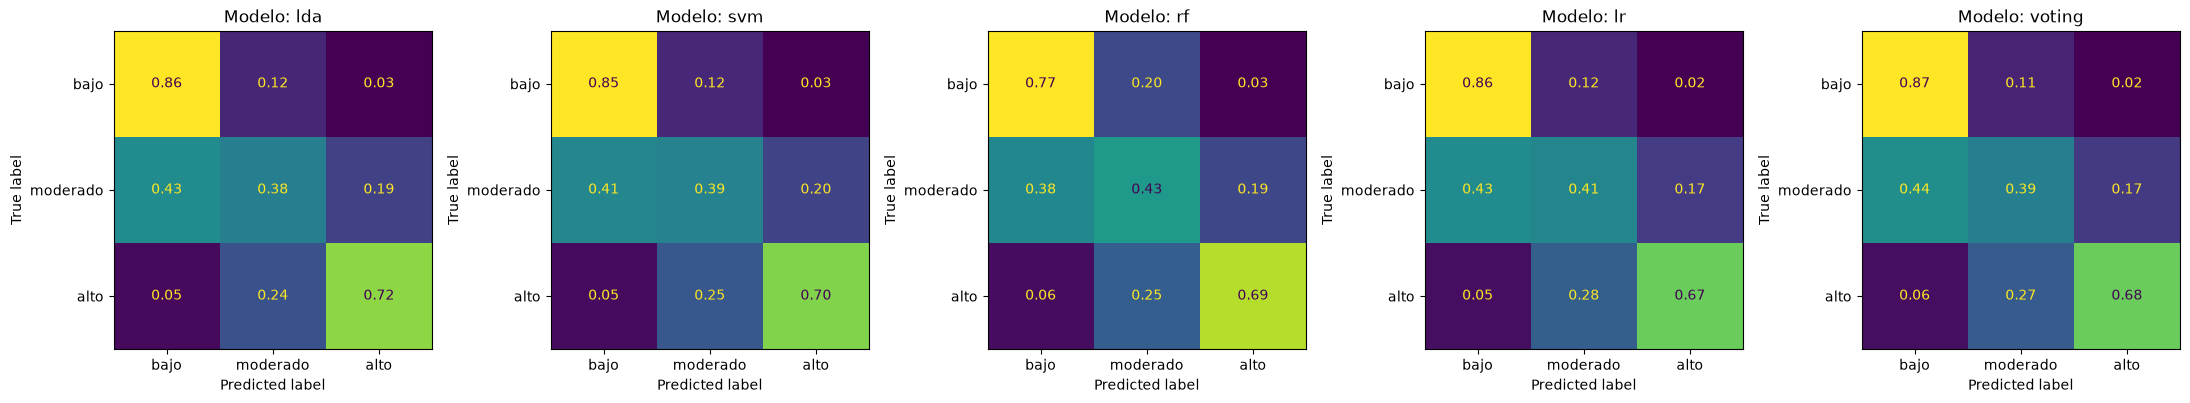

In [192]:
fig, axes = plt.subplots(1, 5, figsize=(22, 4))

for ax, (nombre, busqueda) in zip(axes, busquedas.items()):
    y_pred = cross_val_predict(
        busqueda.best_estimator_,
        X_train,
        y_train,
        cv=mod.validador,
        n_jobs=-1
    )

    ConfusionMatrixDisplay.from_predictions(
        y_train,
        y_pred,
        display_labels=["bajo", "moderado", "alto"],
        normalize="true",
        values_format=".2f",
        ax=ax,
        colorbar=False
    )
    ax.set_title(f"Modelo: {nombre}")

plt.tight_layout()
plt.show()